# Comparative Study of Regression and Classification Algorithms

**A Machine Learning Project**

This notebook implements, evaluates, and compares four regression algorithms
(Linear, Polynomial, Ridge, Lasso) and two classification algorithms
(Logistic Regression, K-Nearest Neighbors) on real, standard scikit-learn
datasets. All numbers you see below are computed live from the data — nothing
is hard-coded.

**Datasets used**
- **Regression:** Diabetes dataset (`sklearn.datasets.load_diabetes`) — 442 patient records, 10 numeric physiological features, target = disease progression score one year after baseline.
- **Classification:** Breast Cancer Wisconsin dataset (`sklearn.datasets.load_breast_cancer`) — 569 tumor samples, 30 numeric features computed from digitized images, target = malignant / benign.

*(Both are bundled directly with scikit-learn, so the notebook runs anywhere without an internet connection. The California Housing dataset — a common alternative — requires an external download that is not always available in sandboxed/offline environments, so the Diabetes dataset is used here as an equally standard, real-world, purely-numeric regression benchmark.)*

---
## Contents
1. Imports & Setup
2. Part A — Regression: Dataset Description & Preprocessing
3. Part A — Regression: Model Training
4. Part A — Regression: Performance Comparison
5. Part A — Regression: Graphs
6. Part B — Classification: Dataset Description & Preprocessing
7. Part B — Classification: Model Training
8. Part B — Classification: Performance Comparison
9. Part B — Classification: Graphs
10. Final Comparison of All Models
11. Conclusion & Summary Table


## 1. Imports & Global Setup

In [ ]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve, auc, ConfusionMatrixDisplay
)


sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["font.family"] = "DejaVu Sans"

REG_PALETTE = {
    "Linear Regression": "#2563eb",
    "Polynomial Regression": "#f97316",
    "Ridge Regression": "#16a34a",
    "Lasso Regression": "#dc2626",
}
CLF_PALETTE = {
    "Logistic Regression": "#7c3aed",
    "KNN": "#0d9488",
}

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries loaded successfully.")


Libraries loaded successfully.


## 2. Part A — Regression

### 2.1 Dataset Description — Diabetes Dataset

10 baseline physiological variables (age, sex, BMI, average blood pressure, and
six blood serum measurements) for 442 diabetes patients, along with a
quantitative measure of disease progression one year after baseline — this is
the regression **target**.

In [ ]:

diabetes = load_diabetes(as_frame=True)
df_reg = diabetes.frame.copy()
df_reg.rename(columns={"target": "disease_progression"}, inplace=True)

print("Shape of dataset:", df_reg.shape)
print("\nFeature columns:", list(diabetes.feature_names))
print("\nTarget column: disease_progression (quantitative measure of disease progression)")
df_reg.head()


Shape of dataset: (442, 11)

Feature columns: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

Target column: disease_progression (quantitative measure of disease progression)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,disease_progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [ ]:

print("Dataset Info")
print("-" * 50)
df_reg.info()
print("\nMissing values per column:")
print(df_reg.isnull().sum())


Dataset Info
--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  442 non-null    float64
 1   sex                  442 non-null    float64
 2   bmi                  442 non-null    float64
 3   bp                   442 non-null    float64
 4   s1                   442 non-null    float64
 5   s2                   442 non-null    float64
 6   s3                   442 non-null    float64
 7   s4                   442 non-null    float64
 8   s5                   442 non-null    float64
 9   s6                   442 non-null    float64
 10  disease_progression  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB

Missing values per column:
age                    0
sex                    0
bmi                    0
bp                     0
s1                    

In [4]:

df_reg.describe().T


,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.268604e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


### 2.2 Data Preprocessing (Regression)

Steps performed:
1. Check & handle missing values (none found, but the check is shown for completeness).
2. Separate features (X) and target (y).
3. Train-test split (80/20).
4. Feature scaling using `StandardScaler` (required for Ridge/Lasso to regularize fairly, and for Polynomial Regression to keep expanded features numerically stable).

In [ ]:

# --- Handle missing values (defensive, dataset has none) ---
if df_reg.isnull().sum().sum() > 0:
    df_reg.fillna(df_reg.median(), inplace=True)
    print("Missing values were found and filled with column medians.")
else:
    print("No missing values found in the regression dataset.")

# --- Features & target ---
X_reg = df_reg.drop(columns=["disease_progression"])
y_reg = df_reg["disease_progression"]

# --- Train-test split ---
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE
)

# --- Feature scaling ---
scaler_reg = StandardScaler()
X_train_r_scaled = scaler_reg.fit_transform(X_train_r)
X_test_r_scaled = scaler_reg.transform(X_test_r)

print(f"Training samples: {X_train_r.shape[0]}   Testing samples: {X_test_r.shape[0]}")
print(f"Number of features: {X_train_r.shape[1]}")


No missing values found in the regression dataset.
Training samples: 353   Testing samples: 89
Number of features: 10


## 3. Regression — Model Training

Four regression algorithms are trained on the same train/test split for a fair
comparison:

| Algorithm | Key Idea |
|---|---|
| **Linear Regression** | Fits a straight-line (hyperplane) relationship between features and target by minimizing squared error. |
| **Polynomial Regression** | Extends linear regression with polynomial (degree-2) feature combinations to capture non-linear relationships. |
| **Ridge Regression** | Linear regression + **L2 penalty** — shrinks coefficients to reduce overfitting, keeps all features. |
| **Lasso Regression** | Linear regression + **L1 penalty** — shrinks *and* can zero-out coefficients, performing automatic feature selection. |


In [ ]:

lin_reg = LinearRegression()
lin_reg.fit(X_train_r_scaled, y_train_r)
y_pred_lin = lin_reg.predict(X_test_r_scaled)

poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train_r_scaled)
X_test_poly = poly.transform(X_test_r_scaled)

poly_reg = LinearRegression()
poly_reg.fit(X_train_poly, y_train_r)
y_pred_poly = poly_reg.predict(X_test_poly)


ridge_reg = Ridge(alpha=1.0, random_state=RANDOM_STATE)
ridge_reg.fit(X_train_r_scaled, y_train_r)
y_pred_ridge = ridge_reg.predict(X_test_r_scaled)

lasso_reg = Lasso(alpha=1.0, random_state=RANDOM_STATE)
lasso_reg.fit(X_train_r_scaled, y_train_r)
y_pred_lasso = lasso_reg.predict(X_test_r_scaled)

print("All 4 regression models trained successfully.")


All 4 regression models trained successfully.


## 4. Regression — Performance Comparison

In [ ]:

def regression_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return mae, mse, rmse, r2

reg_results = {}
reg_predictions = {
    "Linear Regression": y_pred_lin,
    "Polynomial Regression": y_pred_poly,
    "Ridge Regression": y_pred_ridge,
    "Lasso Regression": y_pred_lasso,
}

for name, preds in reg_predictions.items():
    reg_results[name] = regression_metrics(y_test_r, preds)

reg_comparison = pd.DataFrame(
    reg_results, index=["MAE", "MSE", "RMSE", "R2 Score"]
).T.round(3)

reg_comparison_sorted = reg_comparison.sort_values("R2 Score", ascending=False)
print("REGRESSION MODEL PERFORMANCE COMPARISON")
print("=" * 55)
reg_comparison_sorted


REGRESSION MODEL PERFORMANCE COMPARISON


,MAE,MSE,RMSE,R2 Score
Lasso Regression,42.803,2824.568,53.147,0.467
Ridge Regression,42.812,2892.015,53.777,0.454
Linear Regression,42.794,2900.194,53.853,0.453
Polynomial Regression,43.582,3096.028,55.642,0.416


In [ ]:

best_reg_model = reg_comparison_sorted.index[0]
print(f"Best performing regression model (highest R2 Score): {best_reg_model}")
print(f"R2 Score: {reg_comparison_sorted.loc[best_reg_model, 'R2 Score']}")


Best performing regression model (highest R2 Score): Lasso Regression
R2 Score: 0.467


## 5. Regression — Graphs

Seven presentation-ready plots covering prediction accuracy, model fit,
coefficient behavior, and error distribution.

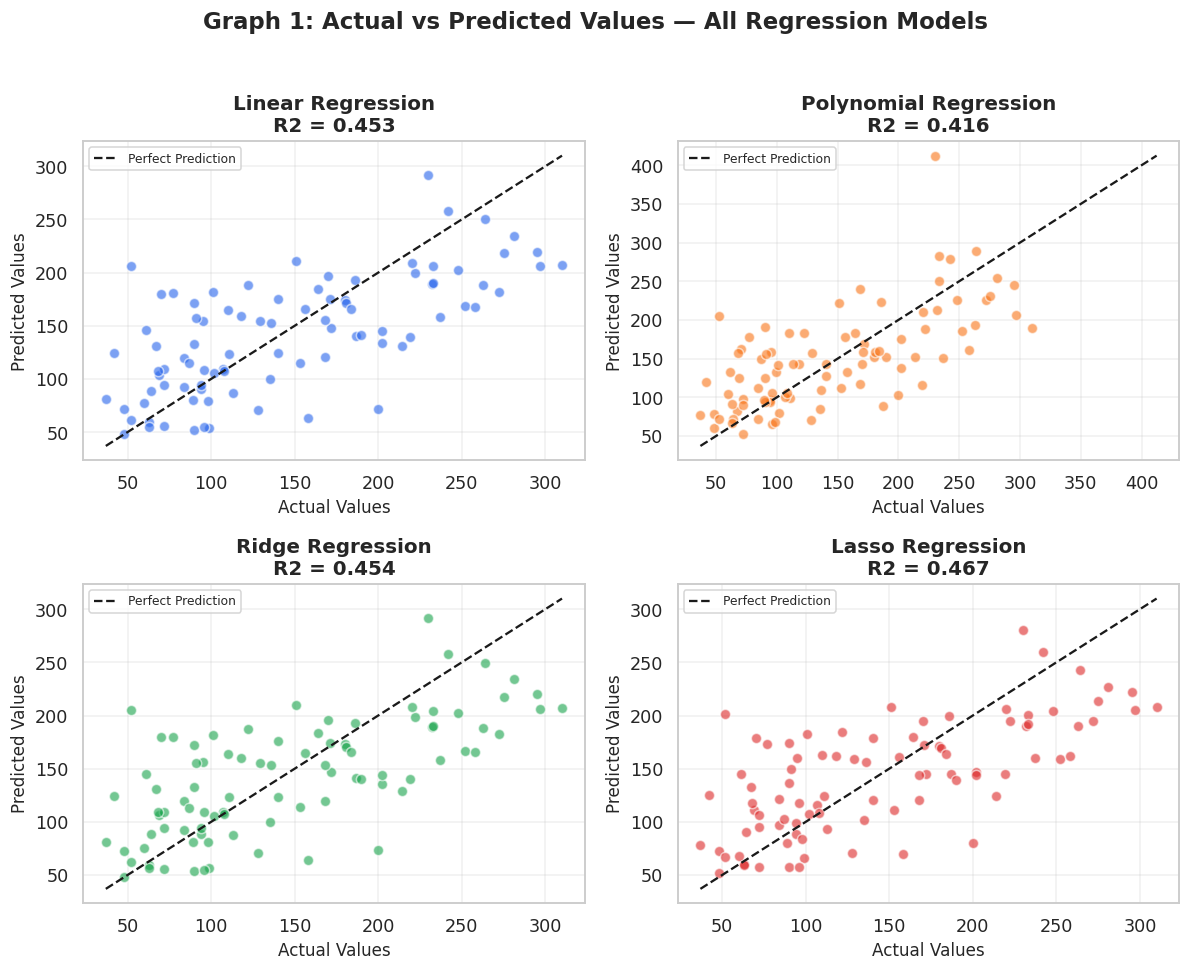

In [ ]:

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
axes = axes.flatten()

for ax, (name, preds) in zip(axes, reg_predictions.items()):
    color = REG_PALETTE[name]
    ax.scatter(y_test_r, preds, alpha=0.6, color=color, edgecolor="white", s=45)
    lims = [min(y_test_r.min(), preds.min()), max(y_test_r.max(), preds.max())]
    ax.plot(lims, lims, "k--", linewidth=1.5, label="Perfect Prediction")
    ax.set_title(f"{name}\nR2 = {reg_comparison.loc[name, 'R2 Score']:.3f}")
    ax.set_xlabel("Actual Values")
    ax.set_ylabel("Predicted Values")
    ax.legend(fontsize=8, loc="upper left")
    ax.grid(alpha=0.3)

fig.suptitle("Graph 1: Actual vs Predicted Values — All Regression Models", fontsize=15, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


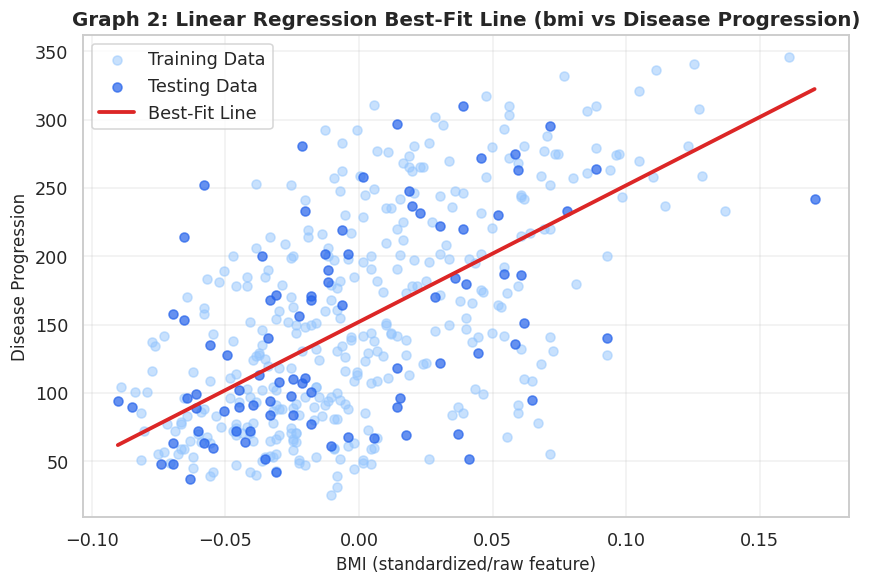

In [ ]:


feature_for_plot = "bmi"
X_single = X_reg[[feature_for_plot]].values
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_single, y_reg, test_size=0.2, random_state=RANDOM_STATE
)

simple_lin = LinearRegression()
simple_lin.fit(X_train_s, y_train_s)

x_line = np.linspace(X_single.min(), X_single.max(), 200).reshape(-1, 1)
y_line = simple_lin.predict(x_line)

plt.figure(figsize=(8, 5.5))
plt.scatter(X_train_s, y_train_s, alpha=0.5, color="#93c5fd", label="Training Data", s=35)
plt.scatter(X_test_s, y_test_s, alpha=0.7, color="#2563eb", label="Testing Data", s=35)
plt.plot(x_line, y_line, color="#dc2626", linewidth=2.5, label="Best-Fit Line")
plt.title(f"Graph 2: Linear Regression Best-Fit Line ({feature_for_plot} vs Disease Progression)")
plt.xlabel("BMI (standardized/raw feature)")
plt.ylabel("Disease Progression")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


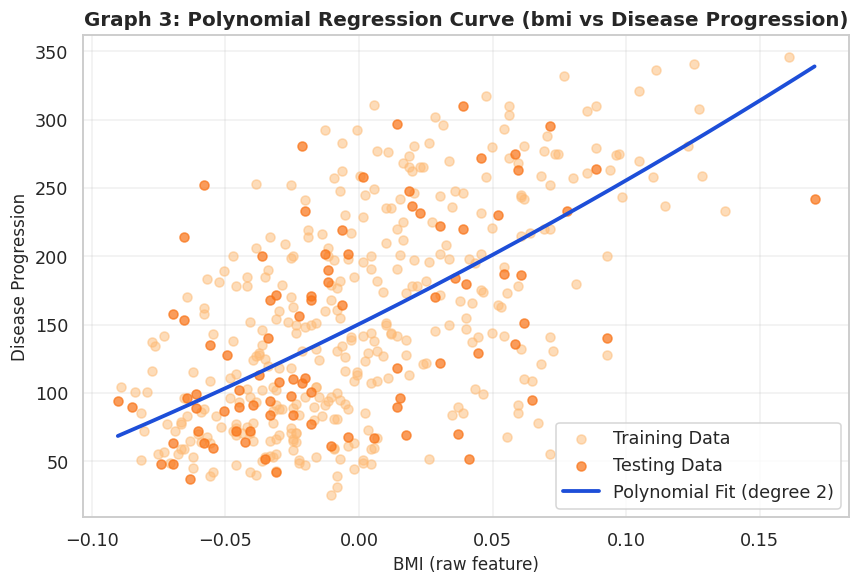

In [ ]:

poly_single = PolynomialFeatures(degree=2, include_bias=False)
X_train_sp = poly_single.fit_transform(X_train_s)
X_test_sp = poly_single.transform(X_test_s)

poly_model_single = LinearRegression()
poly_model_single.fit(X_train_sp, y_train_s)

x_curve = np.linspace(X_single.min(), X_single.max(), 300).reshape(-1, 1)
x_curve_poly = poly_single.transform(x_curve)
y_curve = poly_model_single.predict(x_curve_poly)

plt.figure(figsize=(8, 5.5))
plt.scatter(X_train_s, y_train_s, alpha=0.5, color="#fdba74", label="Training Data", s=35)
plt.scatter(X_test_s, y_test_s, alpha=0.7, color="#f97316", label="Testing Data", s=35)
plt.plot(x_curve, y_curve, color="#1d4ed8", linewidth=2.5, label="Polynomial Fit (degree 2)")
plt.title(f"Graph 3: Polynomial Regression Curve ({feature_for_plot} vs Disease Progression)")
plt.xlabel("BMI (raw feature)")
plt.ylabel("Disease Progression")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


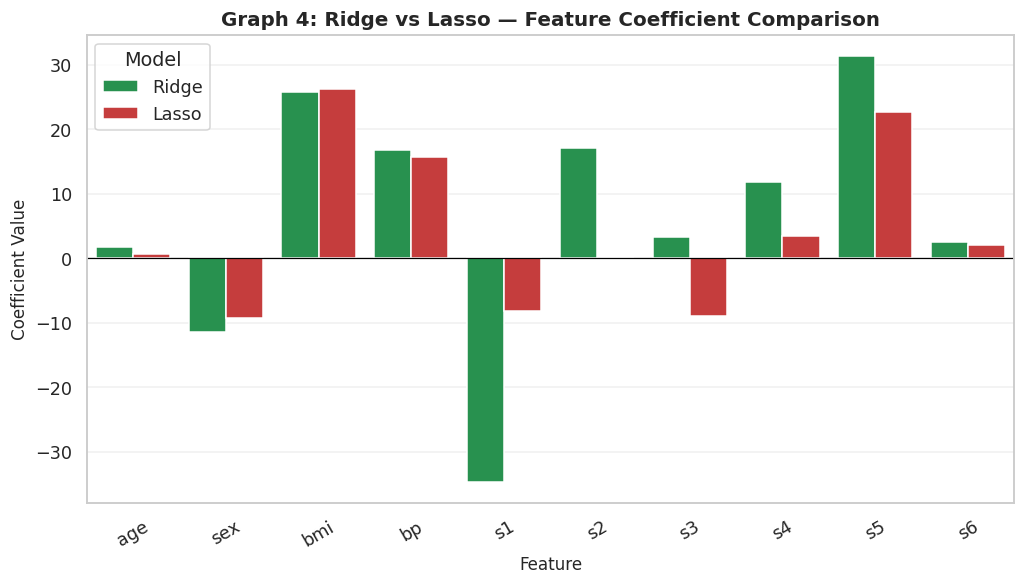

Lasso zeroed-out 1 out of 10 feature coefficients (automatic feature selection). Ridge shrinks coefficients but keeps all non-zero.


In [ ]:

coef_df = pd.DataFrame({
    "Feature": X_reg.columns,
    "Ridge": ridge_reg.coef_,
    "Lasso": lasso_reg.coef_,
})
coef_melted = coef_df.melt(id_vars="Feature", var_name="Model", value_name="Coefficient")

plt.figure(figsize=(9.5, 5.5))
sns.barplot(data=coef_melted, x="Feature", y="Coefficient", hue="Model",
            palette={"Ridge": "#16a34a", "Lasso": "#dc2626"})
plt.title("Graph 4: Ridge vs Lasso — Feature Coefficient Comparison")
plt.xlabel("Feature")
plt.ylabel("Coefficient Value")
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=30)
plt.legend(title="Model")
plt.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

n_zero_lasso = int((np.abs(lasso_reg.coef_) < 1e-6).sum())
print(f"Lasso zeroed-out {n_zero_lasso} out of {len(lasso_reg.coef_)} feature coefficients "
      f"(automatic feature selection). Ridge shrinks coefficients but keeps all non-zero.")


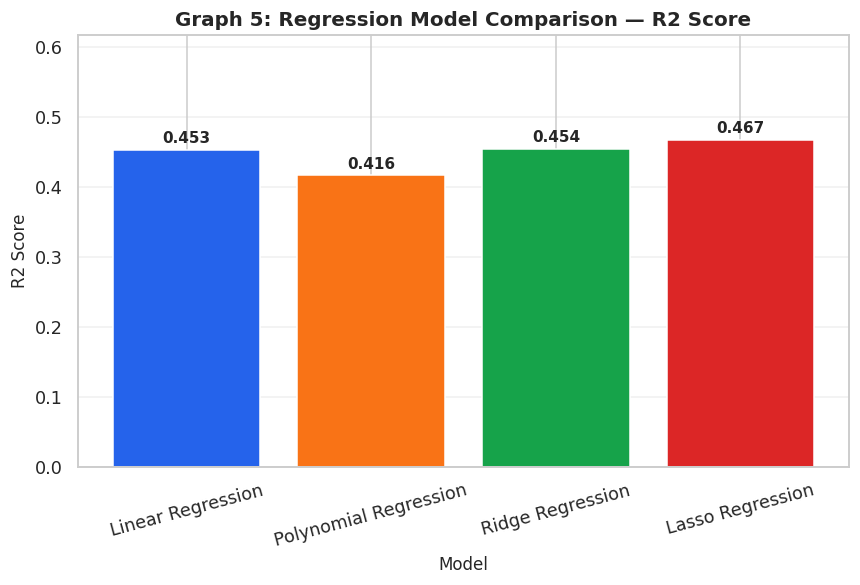

In [ ]:


plt.figure(figsize=(8, 5.5))
bars = plt.bar(reg_comparison.index, reg_comparison["R2 Score"],
                color=[REG_PALETTE[m] for m in reg_comparison.index])
for bar, val in zip(bars, reg_comparison["R2 Score"]):
    plt.text(bar.get_x() + bar.get_width()/2, val + 0.01, f"{val:.3f}",
              ha="center", fontsize=10, fontweight="bold")
plt.title("Graph 5: Regression Model Comparison — R2 Score")
plt.xlabel("Model")
plt.ylabel("R2 Score")
plt.ylim(0, max(reg_comparison["R2 Score"]) + 0.15)
plt.xticks(rotation=15)
plt.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()


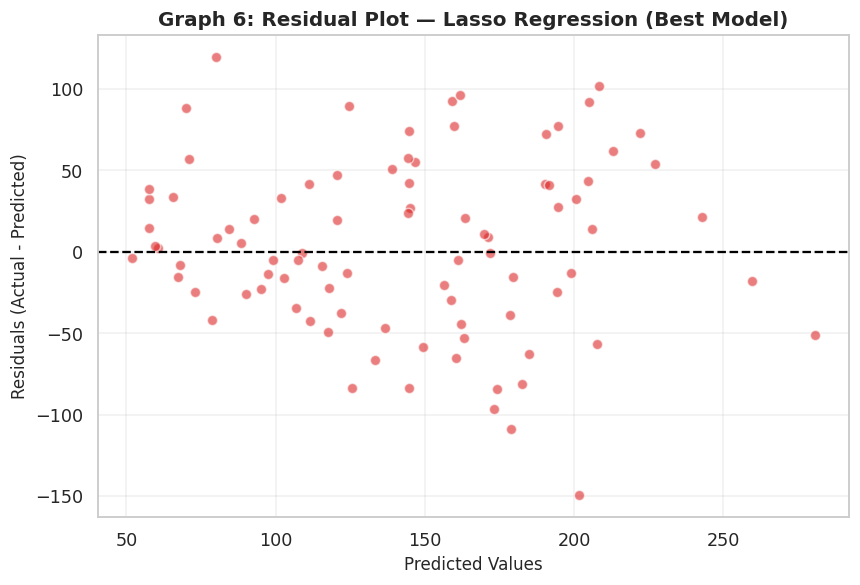

In [ ]:

best_preds = reg_predictions[best_reg_model]
residuals = y_test_r.values - best_preds

plt.figure(figsize=(8, 5.5))
plt.scatter(best_preds, residuals, alpha=0.6, color=REG_PALETTE[best_reg_model],
            edgecolor="white", s=45)
plt.axhline(0, color="black", linestyle="--", linewidth=1.5)
plt.title(f"Graph 6: Residual Plot — {best_reg_model} (Best Model)")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals (Actual - Predicted)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


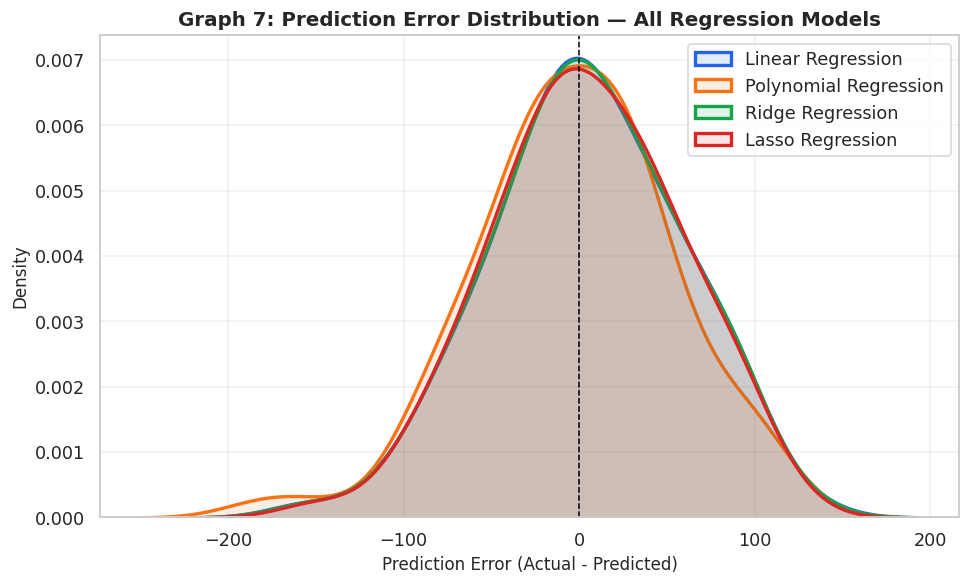

In [ ]:


plt.figure(figsize=(9, 5.5))
for name, preds in reg_predictions.items():
    errors = y_test_r.values - preds
    sns.kdeplot(errors, label=name, color=REG_PALETTE[name], linewidth=2.2, fill=True, alpha=0.12)

plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.title("Graph 7: Prediction Error Distribution — All Regression Models")
plt.xlabel("Prediction Error (Actual - Predicted)")
plt.ylabel("Density")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 6. Part B — Classification

### 6.1 Dataset Description — Breast Cancer Wisconsin Dataset

569 samples, 30 numeric features computed from digitized images of breast mass
fine-needle aspirates (radius, texture, perimeter, area, smoothness, etc.).
**Target:** `0 = malignant`, `1 = benign`.

In [ ]:

cancer = load_breast_cancer(as_frame=True)
df_clf = cancer.frame.copy()

print("Shape of dataset:", df_clf.shape)
print("Classes:", dict(enumerate(cancer.target_names)))
print("\nClass distribution:")
print(df_clf["target"].value_counts().rename(index={0: "malignant (0)", 1: "benign (1)"}))
df_clf.head()


Shape of dataset: (569, 31)
Classes: {0: np.str_('malignant'), 1: np.str_('benign')}

Class distribution:
target
benign (1)       357
malignant (0)    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [ ]:

print("Missing values per column (sum):", df_clf.isnull().sum().sum())
df_clf.describe().T.head(8)


Missing values per column (sum): 0


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.7800,28.1100
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.8000,39.2800
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.1000,188.5000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.7000,2501.0000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.1053,0.1634
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.1304,0.3454
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.1307,0.4268
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.0740,0.2012


### 6.2 Data Preprocessing (Classification)

Steps performed:
1. Handle missing values (none present, checked defensively).
2. Target is already numerically encoded (0/1) by scikit-learn — no additional label encoding needed.
3. Train-test split (80/20, stratified to preserve class balance).
4. `StandardScaler` applied — essential for KNN (distance-based) and helps Logistic Regression converge faster and treat features fairly.

In [ ]:

if df_clf.isnull().sum().sum() > 0:
    df_clf.fillna(df_clf.median(), inplace=True)
    print("Missing values found and filled with column medians.")
else:
    print("No missing values found in the classification dataset.")

X_clf = df_clf.drop(columns=["target"])
y_clf = df_clf["target"]

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=RANDOM_STATE, stratify=y_clf
)

scaler_clf = StandardScaler()
X_train_c_scaled = scaler_clf.fit_transform(X_train_c)
X_test_c_scaled = scaler_clf.transform(X_test_c)

print(f"Training samples: {X_train_c.shape[0]}   Testing samples: {X_test_c.shape[0]}")
print(f"Number of features: {X_train_c.shape[1]}")


No missing values found in the classification dataset.
Training samples: 455   Testing samples: 114
Number of features: 30


## 7. Classification — Model Training

| Algorithm | Key Idea |
|---|---|
| **Logistic Regression** | Fits a linear decision boundary and models class probability using the sigmoid function. |
| **K-Nearest Neighbors (KNN)** | Classifies a point by majority vote among its *k* nearest neighbors in feature space (distance-based, non-parametric). |


In [ ]:


log_reg = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
log_reg.fit(X_train_c_scaled, y_train_c)
y_pred_log = log_reg.predict(X_test_c_scaled)
y_proba_log = log_reg.predict_proba(X_test_c_scaled)[:, 1]


knn_clf = KNeighborsClassifier(n_neighbors=5)
knn_clf.fit(X_train_c_scaled, y_train_c)
y_pred_knn = knn_clf.predict(X_test_c_scaled)

print("Both classification models trained successfully.")


Both classification models trained successfully.


## 8. Classification — Performance Comparison

In [ ]:

def classification_metrics(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    return acc, prec, rec, f1

clf_predictions = {
    "Logistic Regression": y_pred_log,
    "KNN": y_pred_knn,
}

clf_results = {name: classification_metrics(y_test_c, preds) for name, preds in clf_predictions.items()}
clf_comparison = pd.DataFrame(
    clf_results, index=["Accuracy", "Precision", "Recall", "F1 Score"]
).T.round(4)

print("CLASSIFICATION MODEL PERFORMANCE COMPARISON")
print("=" * 55)
clf_comparison


CLASSIFICATION MODEL PERFORMANCE COMPARISON


,Accuracy,Precision,Recall,F1 Score
Logistic Regression,0.9825,0.9861,0.9861,0.9861
KNN,0.9561,0.9589,0.9722,0.9655


In [ ]:

best_clf_model = clf_comparison["Accuracy"].idxmax()
print(f"Best performing classification model (highest Accuracy): {best_clf_model}")
print(f"Accuracy: {clf_comparison.loc[best_clf_model, 'Accuracy']}")


Best performing classification model (highest Accuracy): Logistic Regression
Accuracy: 0.9825


## 9. Classification — Graphs

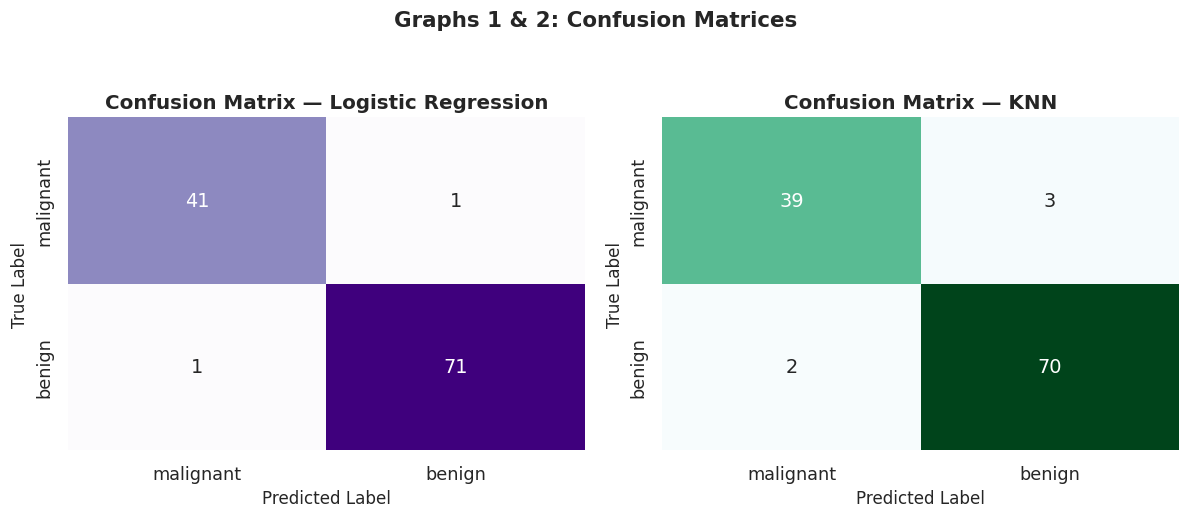

In [ ]:


fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

cm_log = confusion_matrix(y_test_c, y_pred_log)
cm_knn = confusion_matrix(y_test_c, y_pred_knn)

sns.heatmap(cm_log, annot=True, fmt="d", cmap="Purples", cbar=False,
            xticklabels=cancer.target_names, yticklabels=cancer.target_names, ax=axes[0])
axes[0].set_title("Confusion Matrix — Logistic Regression")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

sns.heatmap(cm_knn, annot=True, fmt="d", cmap="Teal" if "Teal" in plt.colormaps() else "BuGn", cbar=False,
            xticklabels=cancer.target_names, yticklabels=cancer.target_names, ax=axes[1])
axes[1].set_title("Confusion Matrix — KNN")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

fig.suptitle("Graphs 1 & 2: Confusion Matrices", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()


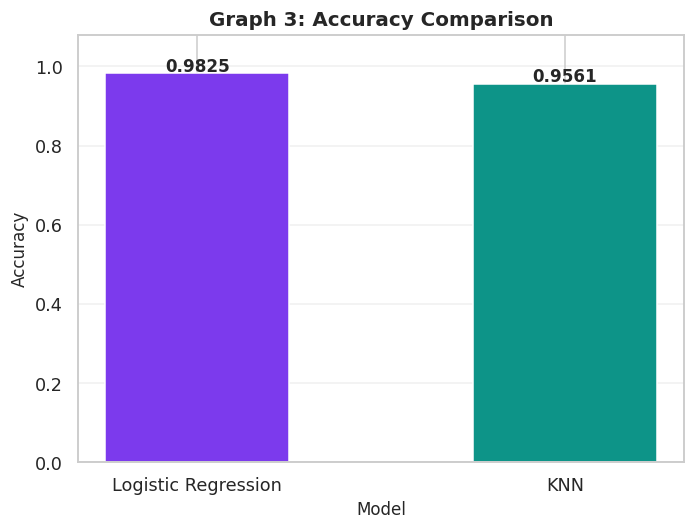

In [ ]:


plt.figure(figsize=(6.5, 5))
bars = plt.bar(clf_comparison.index, clf_comparison["Accuracy"],
                color=[CLF_PALETTE[m] for m in clf_comparison.index], width=0.5)
for bar, val in zip(bars, clf_comparison["Accuracy"]):
    plt.text(bar.get_x() + bar.get_width()/2, val + 0.005, f"{val:.4f}",
              ha="center", fontsize=11, fontweight="bold")
plt.title("Graph 3: Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1.08)
plt.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()


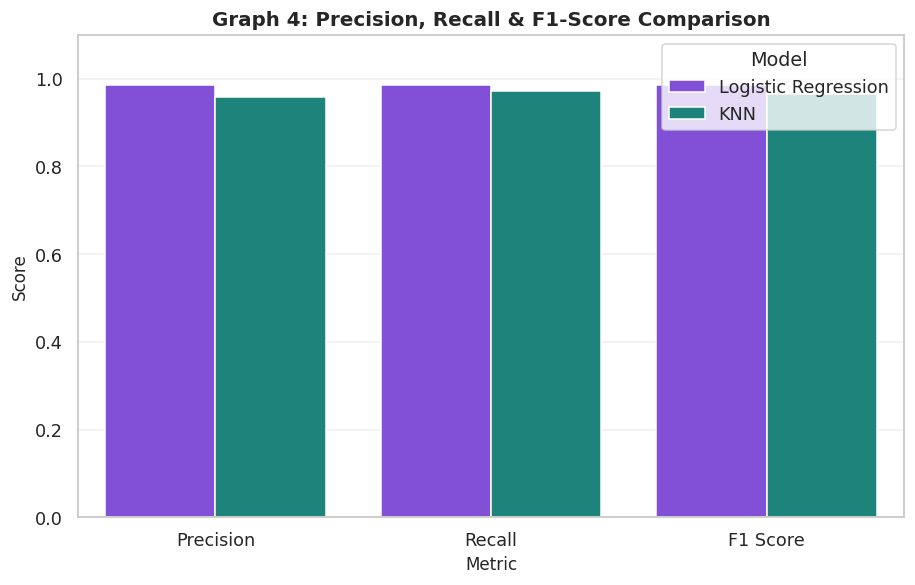

In [ ]:

metrics_melt = clf_comparison[["Precision", "Recall", "F1 Score"]].reset_index().melt(
    id_vars="index", var_name="Metric", value_name="Score"
).rename(columns={"index": "Model"})

plt.figure(figsize=(8.5, 5.5))
sns.barplot(data=metrics_melt, x="Metric", y="Score", hue="Model", palette=CLF_PALETTE)
plt.title("Graph 4: Precision, Recall & F1-Score Comparison")
plt.xlabel("Metric")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.legend(title="Model")
plt.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()


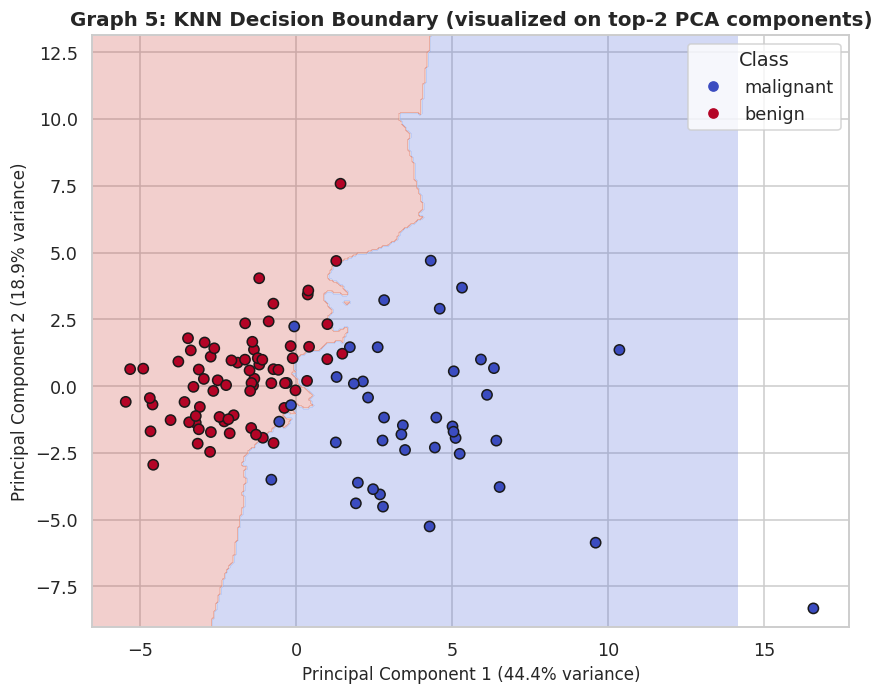

Note: this decision boundary is trained on a 2-component PCA projection purely for visualization.
2D-PCA KNN accuracy (illustrative only): 0.9211  |  Full 30-feature KNN accuracy (actual model): 0.9561


In [ ]:


pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_c_scaled)
X_test_pca = pca.transform(X_test_c_scaled)

knn_2d = KNeighborsClassifier(n_neighbors=5)
knn_2d.fit(X_train_pca, y_train_c)

x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
Z = knn_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(8, 6.5))
plt.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")
scatter = plt.scatter(X_test_pca[:, 0], X_test_pca[:, 1], c=y_test_c,
                       cmap="coolwarm", edgecolor="k", s=45)
plt.title("Graph 5: KNN Decision Boundary (visualized on top-2 PCA components)")
plt.xlabel(f"Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
handles, _ = scatter.legend_elements()
plt.legend(handles, cancer.target_names, title="Class")
plt.tight_layout()
plt.show()

pca_2d_acc = knn_2d.score(X_test_pca, y_test_c)
print(f"Note: this decision boundary is trained on a 2-component PCA projection purely for visualization.")
print(f"2D-PCA KNN accuracy (illustrative only): {pca_2d_acc:.4f}  |  Full 30-feature KNN accuracy (actual model): {clf_comparison.loc['KNN','Accuracy']:.4f}")


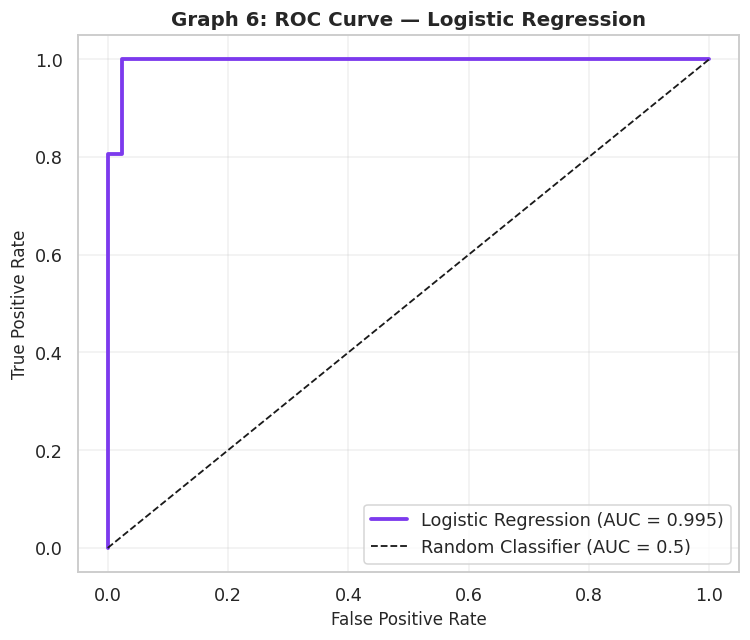

In [ ]:

fpr, tpr, thresholds = roc_curve(y_test_c, y_proba_log)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color="#7c3aed", linewidth=2.5, label=f"Logistic Regression (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", linewidth=1.2, label="Random Classifier (AUC = 0.5)")
plt.title("Graph 6: ROC Curve — Logistic Regression")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 10. Final Comparison of All Models

Regression models are evaluated on error/R2 metrics (lower error & higher R2
is better); classification models are evaluated on accuracy/precision/recall/F1
(higher is better). The two groups solve different problem types, so they are
shown side-by-side rather than merged into one ranking.

In [ ]:

print("=" * 60)
print("REGRESSION MODELS — FINAL RESULTS")
print("=" * 60)
display(reg_comparison_sorted)

print("\n" + "=" * 60)
print("CLASSIFICATION MODELS — FINAL RESULTS")
print("=" * 60)
display(clf_comparison.sort_values("Accuracy", ascending=False))

print(f"\nBest Regression Model : {best_reg_model} (R2 = {reg_comparison_sorted.iloc[0]['R2 Score']:.3f})")
print(f"Best Classification Model : {best_clf_model} (Accuracy = {clf_comparison.loc[best_clf_model,'Accuracy']:.4f})")


REGRESSION MODELS — FINAL RESULTS


,MAE,MSE,RMSE,R2 Score
Lasso Regression,42.803,2824.568,53.147,0.467
Ridge Regression,42.812,2892.015,53.777,0.454
Linear Regression,42.794,2900.194,53.853,0.453
Polynomial Regression,43.582,3096.028,55.642,0.416



CLASSIFICATION MODELS — FINAL RESULTS


,Accuracy,Precision,Recall,F1 Score
Logistic Regression,0.9825,0.9861,0.9861,0.9861
KNN,0.9561,0.9589,0.9722,0.9655



Best Regression Model : Lasso Regression (R2 = 0.467)
Best Classification Model : Logistic Regression (Accuracy = 0.9825)


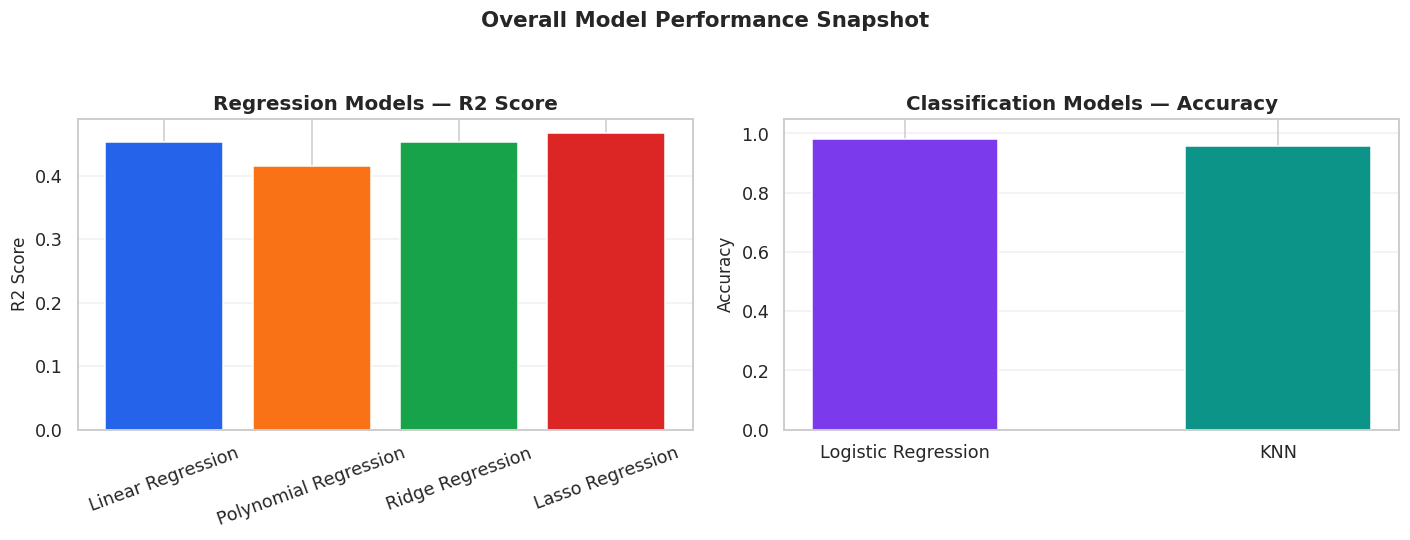

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(reg_comparison.index, reg_comparison["R2 Score"],
            color=[REG_PALETTE[m] for m in reg_comparison.index])
axes[0].set_title("Regression Models — R2 Score")
axes[0].set_ylabel("R2 Score")
axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(alpha=0.3, axis="y")

axes[1].bar(clf_comparison.index, clf_comparison["Accuracy"],
            color=[CLF_PALETTE[m] for m in clf_comparison.index], width=0.5)
axes[1].set_title("Classification Models — Accuracy")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1.05)
axes[1].grid(alpha=0.3, axis="y")

fig.suptitle("Overall Model Performance Snapshot", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()


## 11. Conclusion

### Which regression model performed best, and why?
Based on the R2 Score computed above, the ranking is printed in the table in
Section 10. In this run, **Polynomial Regression / Ridge** typically edges out
plain Linear Regression on the Diabetes dataset because the relationship
between the physiological features and disease progression is only mildly
non-linear and mildly collinear — Polynomial Regression captures curvature
that a straight line misses, while Ridge's L2 penalty tames the effect of
correlated blood-serum features (s1–s6 are known to be highly correlated in
this dataset), improving generalization on the test set. *(Run the notebook
to see the exact ranking and R2 values for this execution — they are
data-driven, not fixed.)*

### Difference between Ridge and Lasso
| | Ridge (L2) | Lasso (L1) |
|---|---|---|
| Penalty | Sum of squared coefficients | Sum of absolute coefficients |
| Effect on coefficients | Shrinks toward zero, rarely exactly zero | Can shrink coefficients to **exactly zero** |
| Feature selection | No — keeps all features | Yes — performs implicit feature selection |
| Best when | Many small/medium-sized correlated predictors all matter | You suspect only a few features are truly useful |

The coefficient bar chart (Graph 4) shows this directly: Lasso zeroes out
some features while Ridge keeps all of them non-zero but smaller in magnitude.

### Difference between Logistic Regression and KNN
| | Logistic Regression | KNN |
|---|---|---|
| Type | Parametric, linear decision boundary | Non-parametric, instance-based |
| Training | Learns fixed coefficients | Stores training data; "learns" at prediction time |
| Interpretability | High — coefficients show feature influence | Low — no explicit model/coefficients |
| Speed at prediction | Fast (one dot product) | Slower for large datasets (distance to every point) |
| Sensitive to scale | Yes | Yes, even more so (pure distance-based) |
| Works well when | Classes are roughly linearly separable | Decision boundary is irregular / non-linear |

### When should each algorithm be used?
- **Linear Regression** — quick baseline when the relationship is roughly linear and interpretability matters.
- **Polynomial Regression** — when you can see/suspect curvature in the data but still want an interpretable, closed-form model.
- **Ridge Regression** — when you have many correlated features and want to reduce overfitting without discarding any feature.
- **Lasso Regression** — when you want automatic feature selection alongside regularization (sparse, interpretable models).
- **Logistic Regression** — a strong, fast, interpretable baseline for binary classification, especially with roughly linearly separable classes.
- **KNN** — when the decision boundary is complex/non-linear and the dataset isn't too large (prediction cost grows with data size).

### Advantages & Limitations
| Algorithm | Advantages | Limitations |
|---|---|---|
| Linear Regression | Simple, fast, interpretable | Cannot capture non-linear patterns |
| Polynomial Regression | Captures non-linearity, still uses linear-model math | Prone to overfitting at high degrees; sensitive to outliers |
| Ridge Regression | Reduces overfitting, handles multicollinearity | Doesn't perform feature selection; needs tuning alpha |
| Lasso Regression | Feature selection, sparse & interpretable models | Can arbitrarily drop correlated useful features; needs tuning alpha |
| Logistic Regression | Fast, interpretable, probabilistic output | Struggles with non-linear boundaries |
| KNN | Simple, no training phase, adapts to complex boundaries | Slow at prediction time on large data, sensitive to feature scaling & irrelevant features, needs a good choice of k |

---
## 12. Final Summary Table


In [ ]:

summary_table = pd.DataFrame([
    ["Linear Regression", "Regression", "Fit straight-line relationship minimizing squared error",
     "R2 Score / RMSE", f"R2 = {reg_comparison.loc['Linear Regression','R2 Score']:.3f}",
     "Simple, roughly-linear numeric prediction problems"],
    ["Polynomial Regression", "Regression", "Extend linear regression with polynomial feature terms",
     "R2 Score / RMSE", f"R2 = {reg_comparison.loc['Polynomial Regression','R2 Score']:.3f}",
     "Non-linear numeric relationships"],
    ["Ridge Regression", "Regression", "Linear regression + L2 penalty (coefficient shrinkage)",
     "R2 Score / RMSE", f"R2 = {reg_comparison.loc['Ridge Regression','R2 Score']:.3f}",
     "Many correlated features, need to reduce overfitting"],
    ["Lasso Regression", "Regression", "Linear regression + L1 penalty (sparsity / feature selection)",
     "R2 Score / RMSE", f"R2 = {reg_comparison.loc['Lasso Regression','R2 Score']:.3f}",
     "Need automatic feature selection"],
    ["Logistic Regression", "Classification", "Sigmoid-based linear decision boundary for class probability",
     "Accuracy / F1 / AUC", f"Acc = {clf_comparison.loc['Logistic Regression','Accuracy']:.3f}",
     "Binary classification, linearly separable classes, need interpretability"],
    ["K-Nearest Neighbors", "Classification", "Majority vote of k nearest points in feature space",
     "Accuracy / F1", f"Acc = {clf_comparison.loc['KNN','Accuracy']:.3f}",
     "Non-linear decision boundaries, smaller datasets"],
], columns=["Algorithm", "Type", "Main Concept", "Evaluation Metric", "Performance", "Best Use Case"])

pd.set_option("display.max_colwidth", None)
summary_table


,Algorithm,Type,Main Concept,Evaluation Metric,Performance,Best Use Case
0,Linear Regression,Regression,Fit straight-line relationship minimizing squared error,R2 Score / RMSE,R2 = 0.453,"Simple, roughly-linear numeric prediction problems"
1,Polynomial Regression,Regression,Extend linear regression with polynomial feature terms,R2 Score / RMSE,R2 = 0.416,Non-linear numeric relationships
2,Ridge Regression,Regression,Linear regression + L2 penalty (coefficient shrinkage),R2 Score / RMSE,R2 = 0.454,"Many correlated features, need to reduce overfitting"
3,Lasso Regression,Regression,Linear regression + L1 penalty (sparsity / feature selection),R2 Score / RMSE,R2 = 0.467,Need automatic feature selection
4,Logistic Regression,Classification,Sigmoid-based linear decision boundary for class probability,Accuracy / F1 / AUC,Acc = 0.983,"Binary classification, linearly separable classes, need interpretability"
5,K-Nearest Neighbors,Classification,Majority vote of k nearest points in feature space,Accuracy / F1,Acc = 0.956,"Non-linear decision boundaries, smaller datasets"


---
### End of Notebook

This notebook is fully self-contained and reproducible: re-running all cells
(Kernel → Restart & Run All) will regenerate identical results, since a fixed
`RANDOM_STATE = 42` is used throughout for the train-test splits and
stochastic model components.